This cell installs all the necessary Python libraries required to develop the advanced biomedical Named Entity Recognition (NER) model.

In [ ]:

!pip install -q transformers datasets accelerate
!pip install -q pytorch-crf scikit-learn pandas numpy matplotlib seaborn
!pip install -q networkx


This cell imports the installed libraries and configures the computing environment.

In [ ]:

import os
import re
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)
from torchcrf import CRF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


"In this cell, I load the same Glaucoma Medical Dataset that was used in my previous model. It contains de-identified patient clinical notes and manually annotated medical information. No new dataset is introduced."

In [ ]:

REPO_FOLDER = Path("/content/Glaucoma_Med_Dataset")

if not REPO_FOLDER.exists():
    !git clone https://github.com/jche253/Glaucoma_Med_Dataset.git

NOTES_FOLDER = REPO_FOLDER / "Deidentified_Notes"
ANNOTATIONS_FOLDER = REPO_FOLDER / "Annotations"

note_files = list(NOTES_FOLDER.rglob("*.txt"))
jsonl_files = list(ANNOTATIONS_FOLDER.rglob("*.jsonl"))

if not jsonl_files:
    raise FileNotFoundError("Annotation JSONL not found!")

ANNOTATION_FILE = jsonl_files[0]

print("Clinical notes:", len(note_files))
print("Annotation file:", ANNOTATION_FILE)


Cloning into 'Glaucoma_Med_Dataset'...
remote: Enumerating objects: 527, done.
remote: Counting objects: 100% (527/527), done.
remote: Compressing objects: 100% (519/519), done.
remote: Total 527 (delta 20), reused 487 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (527/527), 1.08 MiB | 10.40 MiB/s, done.
Resolving deltas: 100% (20/20), done.
Clinical notes: 480
Annotation file: /content/Glaucoma_Med_Dataset/Annotations/Combined_annotations.jsonl


"This cell extracts the manually annotated medical entities from the JSONL file. It identifies the exact positions and categories of entities in the clinical text. These annotations act as ground truth for supervised model training."

In [ ]:

records = []

with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:

    for line in file:

        if not line.strip():
            continue

        sanitized_line = re.sub(
            r":\s*\*+\b", ": null", line
        )

        sanitized_line = re.sub(
            r":\s*\*+\s*(,|})", r": null\1",
            sanitized_line
        )

        sanitized_line = re.sub(
            r'\\([^"\\/bfnrtu])', r'\1',
            sanitized_line
        )

        try:
            item = json.loads(sanitized_line)
        except Exception:
            continue

        text = item.get("text", "")
        labels = item.get("labels", [])

        if not text:
            continue

        entities = []

        for label in labels:

            if len(label) < 3:
                continue

            start, end, entity_type = label[:3]

            start = int(start)
            end = int(end)
            entity_type = str(entity_type).upper()

            if 0 <= start < end <= len(text):

                entities.append({
                    "start": start,
                    "end": end,
                    "type": entity_type
                })

        records.append({
            "text": text,
            "entities": entities
        })

print("Total annotated records:", len(records))

entity_types = sorted({
    entity["type"]
    for record in records
    for entity in record["entities"]
})

print("Available entity types:", entity_types)


Total annotated records: 5520
Available entity types: ['***', 'ADHERENCE', 'DOSAGE', 'DRUG', 'DRUG STOP', 'DRUG USE', 'DURATION', 'FREQUENCY', 'ROUTE', 'STRENGTH']


"In this cell, I convert the annotated entities into BIO tagging format. This helps the model identify where each medical entity starts and ends."

In [ ]:

bio_labels = ["O"]

for entity in entity_types:
    bio_labels.extend([
        "B-" + entity,
        "I-" + entity
    ])

label2id = {
    label: index
    for index, label in enumerate(bio_labels)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

NUM_LABELS = len(bio_labels)

print("Number of labels:", NUM_LABELS)
print(label2id)


Number of labels: 21
{'O': 0, 'B-***': 1, 'I-***': 2, 'B-ADHERENCE': 3, 'I-ADHERENCE': 4, 'B-DOSAGE': 5, 'I-DOSAGE': 6, 'B-DRUG': 7, 'I-DRUG': 8, 'B-DRUG STOP': 9, 'I-DRUG STOP': 10, 'B-DRUG USE': 11, 'I-DRUG USE': 12, 'B-DURATION': 13, 'I-DURATION': 14, 'B-FREQUENCY': 15, 'I-FREQUENCY': 16, 'B-ROUTE': 17, 'I-ROUTE': 18, 'B-STRENGTH': 19, 'I-STRENGTH': 20}


"Here, I use BioLinkBERT instead of the previous BioBERT model. It generates contextual biomedical representations that help the system understand medical terminology and clinical context."

In [ ]:

MODEL_NAME = "michiyasunaga/BioLinkBERT-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

encoder = AutoModel.from_pretrained(
    MODEL_NAME
)

print("BioLinkBERT loaded successfully!")


config.json:   0%|          | 0.00/559 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/379 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/447k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  433MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BioLinkBERT loaded successfully!


"In this cell, I develop a hybrid deep learning architecture. BioLinkBERT extracts contextual features, BiLSTM captures sequential dependencies, and CRF improves the consistency of predicted entity sequences. Combining these components creates an advanced biomedical NER architecture."

In [ ]:

class BioLinkBERT_BiLSTM_CRF(nn.Module):

    def __init__(
        self,
        model_name,
        num_labels,
        hidden_size=256,
        dropout=0.3
    ):

        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_name
        )

        transformer_size = (
            self.encoder.config.hidden_size
        )

        self.bilstm = nn.LSTM(
            input_size=transformer_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_labels
        )

        self.crf = CRF(
            num_labels,
            batch_first=True
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        labels=None
    ):

        transformer_output = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        embeddings = transformer_output.last_hidden_state

        lstm_output, _ = self.bilstm(embeddings)

        lstm_output = self.dropout(lstm_output)

        emissions = self.classifier(lstm_output)

        mask = attention_mask.bool()

        if labels is not None:

            loss = -self.crf(
                emissions,
                labels,
                mask=mask,
                reduction="mean"
            )

            return loss

        predictions = self.crf.decode(
            emissions,
            mask=mask
        )

        return predictions, emissions


model = BioLinkBERT_BiLSTM_CRF(
    MODEL_NAME,
    NUM_LABELS
).to(DEVICE)

print("BioLinkBERT + BiLSTM + CRF initialized!")

print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

BioLinkBERT + BiLSTM + CRF initialized!
Total parameters: 110345208


"In this cell, I tokenize the clinical notes and align the manually annotated character positions with the corresponding tokens. This is important because the model learns using token-level labels rather than raw character positions."

In [ ]:

MAX_LENGTH = 256

def encode_record(record):

    text = record["text"]

    encoding = tokenizer(
        text,
        truncation=True,
        max_length=MAX_LENGTH,
        return_offsets_mapping=True
    )

    offsets = encoding["offset_mapping"]

    labels = []

    for token_start, token_end in offsets:

        assigned_label = label2id["O"]

        if token_start == token_end:
            labels.append(assigned_label)
            continue

        for entity in record["entities"]:

            start = entity["start"]
            end = entity["end"]
            entity_type = entity["type"]

            if token_start < end and token_end > start:

                if token_start <= start < token_end:
                    tag = "B-" + entity_type
                else:
                    tag = "I-" + entity_type

                assigned_label = label2id[tag]
                break

        labels.append(assigned_label)

    return {
        "input_ids": encoding["input_ids"],
        "attention_mask": encoding["attention_mask"],
        "labels": labels,
        "offsets": offsets,
        "text": text,
        "entities": record["entities"]
    }


encoded_records = [
    encode_record(record)
    for record in records
]

print("Tokenization completed!")
print("Encoded records:", len(encoded_records))


Tokenization completed!
Encoded records: 5520


"In this cell, I divide the dataset into training, validation and testing sets. The training set teaches the model, the validation set monitors its performance, and the test set measures its generalization on unseen records."

In [ ]:

train_data, temp_data = train_test_split(
    encoded_records,
    test_size=0.20,
    random_state=SEED
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=SEED
)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))


class ClinicalNERDataset(Dataset):

    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index]


def collate_fn(batch):

    max_len = max(
        len(item["input_ids"])
        for item in batch
    )

    pad_id = tokenizer.pad_token_id

    input_ids = []
    attention_masks = []
    labels = []

    for item in batch:

        padding = max_len - len(item["input_ids"])

        input_ids.append(
            item["input_ids"] + [pad_id] * padding
        )

        attention_masks.append(
            item["attention_mask"] + [0] * padding
        )

        labels.append(
            item["labels"] + [0] * padding
        )

    return {
        "input_ids": torch.tensor(
            input_ids, dtype=torch.long
        ),

        "attention_mask": torch.tensor(
            attention_masks, dtype=torch.long
        ),

        "labels": torch.tensor(
            labels, dtype=torch.long
        )
    }


BATCH_SIZE = 8

train_loader = DataLoader(
    ClinicalNERDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    ClinicalNERDataset(val_data),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    ClinicalNERDataset(test_data),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

print("DataLoaders created successfully!")


Training: 4416
Validation: 552
Testing: 552
DataLoaders created successfully!


"In this cell, I configure the hyperparameters required for model training. AdamW optimizes the model weights, while the learning-rate scheduler controls the learning rate to support stable training."

In [ ]:

EPOCHS = 5

LEARNING_RATE = 2e-5

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

print("Optimizer:", optimizer)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)


Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 2e-05
    lr: 0.0
    maximize: False
    weight_decay: 0.01
)
Epochs: 5
Learning rate: 2e-05


"This is the main training stage. The model learns from annotated clinical records over multiple epochs. After every epoch, validation loss is calculated, and the model with the lowest validation loss is saved."

In [ ]:
import os
import torch

# Verification check for required variables
required_vars = ["train_loader", "val_loader", "model", "optimizer", "scheduler", "DEVICE", "EPOCHS"]
missing_vars = [var for var in required_vars if var not in globals()]
if missing_vars:
    raise NameError(
        f"Missing required variables: {missing_vars}. "
        "Please ensure you run all previous cells (data preparation, model instantiation, optimizer setup) before training."
    )

def run_epoch(loader, training=True):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0

    for batch in loader:

        input_ids = batch["input_ids"].to(DEVICE)

        attention_mask = batch[
            "attention_mask"
        ].to(DEVICE)

        labels = batch["labels"].to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            loss = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()
                scheduler.step()

        total_loss += loss.item()

    return total_loss / max(len(loader), 1)


history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

SAVE_PATH = "/content/BioLinkBERT_BiLSTM_CRF"

os.makedirs(SAVE_PATH, exist_ok=True)

for epoch in range(EPOCHS):

    train_loss = run_epoch(
        train_loader,
        training=True
    )

    val_loss = run_epoch(
        val_loader,
        training=False
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            os.path.join(SAVE_PATH, "best_model.pt")
        )

        print("Best model saved!")

print("\nTraining completed!")


Epoch 1/5
Training Loss: 15.6832
Validation Loss: 5.6004
Best model saved!

Epoch 2/5
Training Loss: 4.5949
Validation Loss: 3.3009
Best model saved!

Epoch 3/5
Training Loss: 2.6376
Validation Loss: 2.1892
Best model saved!

Epoch 4/5
Training Loss: 1.8346
Validation Loss: 1.9362
Best model saved!

Epoch 5/5
Training Loss: 1.4309
Validation Loss: 1.8796
Best model saved!

Training completed!


"In this cell, I visualize the training and validation loss curves. These curves help analyze model convergence and understand whether the model is learning effectively or overfitting."

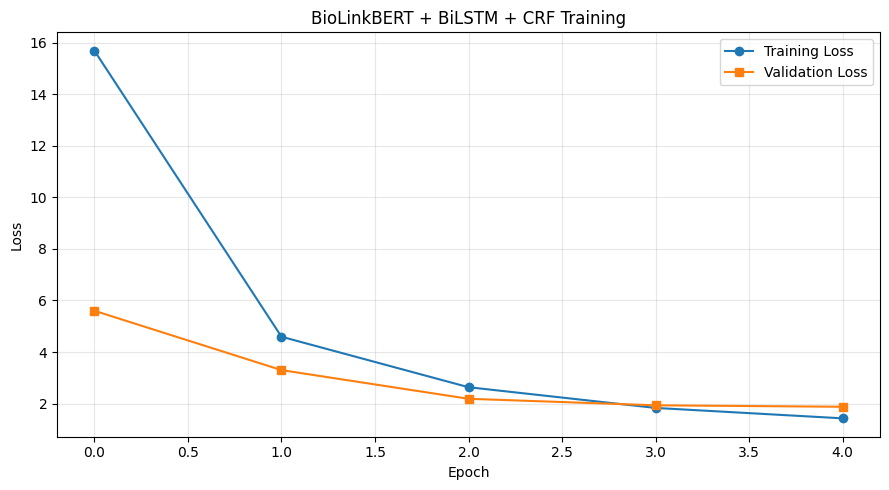

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.title("BioLinkBERT + BiLSTM + CRF Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


"Here, I load the best checkpoint based on validation performance. This ensures that testing is performed using the best saved model rather than simply the last training epoch."

In [ ]:

best_model_path = os.path.join(
    SAVE_PATH,
    "best_model.pt"
)

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

print("Best BioLinkBERT model loaded!")


Best BioLinkBERT model loaded!


In [ ]:

def decode_spans(tags, offsets):

    spans = set()
    current_start = None
    current_end = None
    current_type = None

    def save_current():
        if current_type is not None:
            spans.add((
                current_start,
                current_end,
                current_type
            ))

    for tag, (start, end) in zip(tags, offsets):

        if start == end:
            continue

        if tag == "O":
            save_current()
            current_start = None
            current_end = None
            current_type = None
            continue

        prefix, entity_type = tag.split("-", 1)

        if prefix == "B" or (
            current_type is not None
            and current_type != entity_type
        ):

            save_current()

            current_start = start
            current_end = end
            current_type = entity_type

        elif prefix == "I":

            if current_type is None:

                current_start = start
                current_type = entity_type

            current_end = end

    save_current()

    return spans


def predict_one(item):

    inputs = {
        "input_ids": torch.tensor(
            [item["input_ids"]],
            dtype=torch.long,
            device=DEVICE
        ),

        "attention_mask": torch.tensor(
            [item["attention_mask"]],
            dtype=torch.long,
            device=DEVICE
        )
    }

    with torch.no_grad():

        predicted_ids, emissions = model(
            **inputs
        )

    predicted_tags = [
        id2label[index]
        for index in predicted_ids[0]
    ]

    predicted_spans = decode_spans(
        predicted_tags,
        item["offsets"]
    )

    gold_spans = {
        (
            entity["start"],
            entity["end"],
            entity["type"]
        )
        for entity in item["entities"]
    }

    return predicted_spans, gold_spans, predicted_ids[0]


all_predicted_spans = set()
all_gold_spans = set()

token_true = []
token_pred = []

for item in test_data:

    predicted_spans, gold_spans, predicted_ids = (
        predict_one(item)
    )

    all_predicted_spans.update(
        (item_index, *span)
        for span in predicted_spans
    )

    all_gold_spans.update(
        (item_index, *span)
        for span in gold_spans
    )

    item_index = test_data.index(item)

    for predicted_id, true_id, offset in zip(
        predicted_ids,
        item["labels"],
        item["offsets"]
    ):

        if offset[0] == offset[1]:
            continue

        token_true.append(true_id)
        token_pred.append(predicted_id)

    # Avoid unnecessary repeated processing
    # (item_index is used to keep records separate)


In [ ]:

all_predicted_spans = set()
all_gold_spans = set()

token_true = []
token_pred = []

for item_index, item in enumerate(test_data):

    predicted_spans, gold_spans, predicted_ids = (
        predict_one(item)
    )

    all_predicted_spans.update(
        (item_index, *span)
        for span in predicted_spans
    )

    all_gold_spans.update(
        (item_index, *span)
        for span in gold_spans
    )

    for pred_id, true_id, offset in zip(
        predicted_ids,
        item["labels"],
        item["offsets"]
    ):

        if offset[0] == offset[1]:
            continue

        token_true.append(true_id)
        token_pred.append(pred_id)

TP = len(all_predicted_spans & all_gold_spans)
FP = len(all_predicted_spans - all_gold_spans)
FN = len(all_gold_spans - all_predicted_spans)

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

accuracy = accuracy_score(
    token_true,
    token_pred
) if token_true else 0

print("========== BIO LINKBERT PERFORMANCE ==========")

print(f"Token Accuracy : {accuracy * 100:.2f}%")
print(f"Exact Precision: {precision * 100:.2f}%")
print(f"Exact Recall   : {recall * 100:.2f}%")
print(f"Exact F1 Score : {f1 * 100:.2f}%")


========== BIO LINKBERT PERFORMANCE ==========
Token Accuracy : 97.69%
Exact Precision: 87.56%
Exact Recall   : 89.94%
Exact F1 Score : 88.73%


,Entity,Precision,Recall,F1 Score,Support
0,***,0.0000,0.0000,0.0000,2
1,ADHERENCE,0.5000,0.8750,0.6364,16
2,DOSAGE,0.0000,0.0000,0.0000,2
3,DRUG,0.9272,0.9409,0.9340,203
4,DRUG STOP,0.0000,0.0000,0.0000,6
5,DRUG USE,0.7732,0.8721,0.8197,86
6,DURATION,0.0000,0.0000,0.0000,2
7,FREQUENCY,0.9255,0.9739,0.9490,153
8,ROUTE,0.9097,0.8618,0.8851,152
9,STRENGTH,0.4286,0.7500,0.5455,4


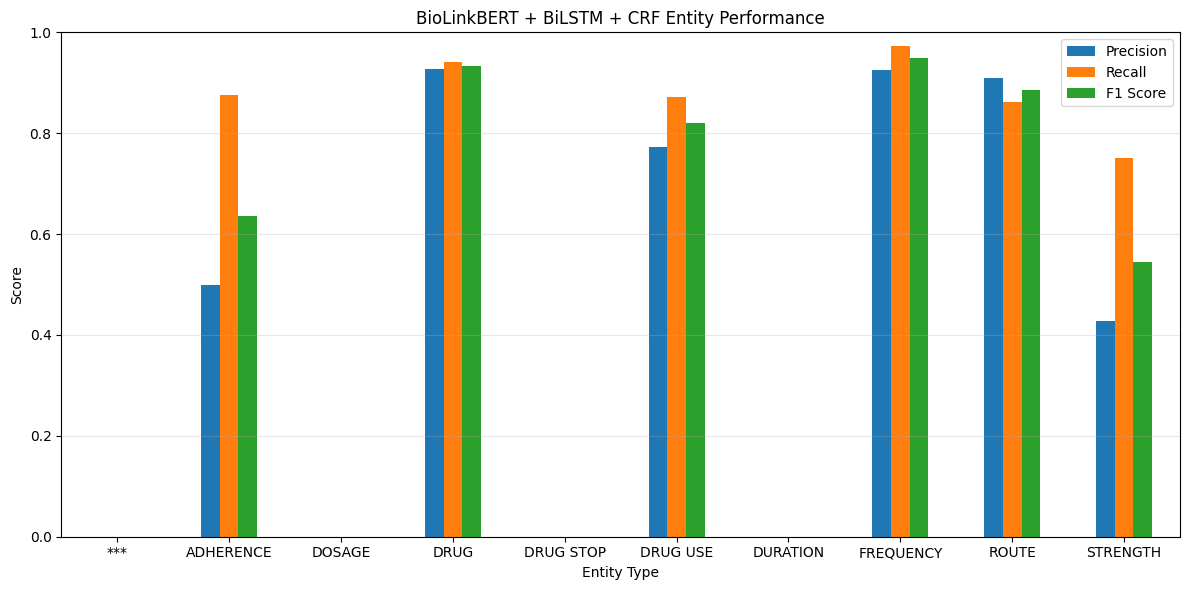

In [ ]:

rows = []

for entity_type in entity_types:

    true_type = {
        span for span in all_gold_spans
        if span[-1] == entity_type
    }

    pred_type = {
        span for span in all_predicted_spans
        if span[-1] == entity_type
    }

    tp = len(true_type & pred_type)
    fp = len(pred_type - true_type)
    fn = len(true_type - pred_type)

    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0

    f = (
        2 * p * r / (p + r)
        if p + r else 0
    )

    rows.append({
        "Entity": entity_type,
        "Precision": p,
        "Recall": r,
        "F1 Score": f,
        "Support": len(true_type)
    })

entity_results = pd.DataFrame(rows)

display(entity_results.round(4))

entity_results.set_index("Entity")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("BioLinkBERT + BiLSTM + CRF Entity Performance")
plt.ylabel("Score")
plt.xlabel("Entity Type")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


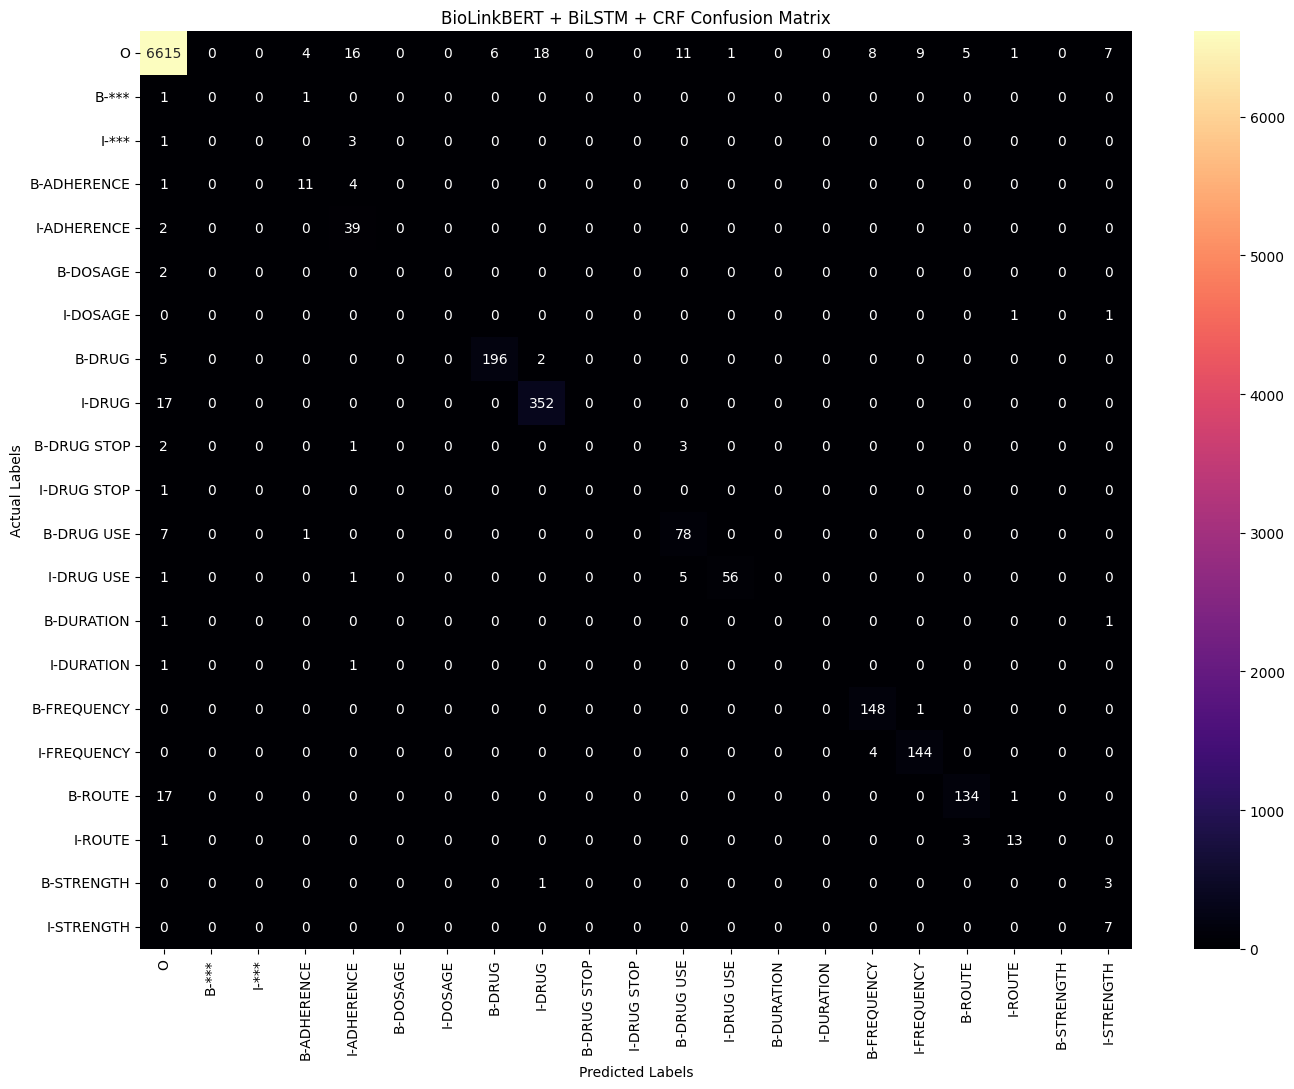

In [ ]:

cm = confusion_matrix(
    token_true,
    token_pred,
    labels=list(range(NUM_LABELS))
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="magma",
    xticklabels=bio_labels,
    yticklabels=bio_labels
)

plt.title("BioLinkBERT + BiLSTM + CRF Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

tokenizer.save_pretrained(SAVE_PATH)

entity_results.to_csv(
    "/content/BioLinkBERT_entity_metrics.csv",
    index=False
)

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Token Accuracy",
        "Exact Precision",
        "Exact Recall",
        "Exact F1 Score"
    ],

    "Score (%)": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

display(evaluation_summary.round(2))

evaluation_summary.to_csv(
    "/content/BioLinkBERT_evaluation.csv",
    index=False
)

print("Model and evaluation results saved!")


,Metric,Score (%)
0,Token Accuracy,97.69
1,Exact Precision,87.56
2,Exact Recall,89.94
3,Exact F1 Score,88.73


Model and evaluation results saved!


In [ ]:

def predict_biolink_entities(text):

    encoding = tokenizer(
        text,
        return_offsets_mapping=True,
        truncation=True,
        max_length=MAX_LENGTH
    )

    offsets = encoding["offset_mapping"]

    inputs = {
        "input_ids": torch.tensor(
            [encoding["input_ids"]],
            dtype=torch.long,
            device=DEVICE
        ),

        "attention_mask": torch.tensor(
            [encoding["attention_mask"]],
            dtype=torch.long,
            device=DEVICE
        )
    }

    model.eval()

    with torch.no_grad():

        predictions, emissions = model(**inputs)

        probabilities = torch.softmax(
            emissions, dim=-1
        )[0]

    results = []

    for span in decode_spans(
        [id2label[x] for x in predictions[0]],
        offsets
    ):

        start, end, entity_type = span

        entity_text = text[start:end]

        results.append({
            "entity": entity_text,
            "label": entity_type,
            "confidence": None,
            "start": start,
            "end": end
        })

    return results


In [ ]:

def extract_entities(text):

    diseases = set()
    drugs = set()

    sentences = get_sentences(text)

    for sentence in sentences:

        # Existing disease recognition
        disease_predictions = run_ner(
            disease_ner,
            sentence
        )

        for item in disease_predictions:

            if not item["label"].endswith("DISEASE"):
                continue

            if item["confidence"] < DISEASE_THRESHOLD:
                continue

            if not is_negated(
                sentence,
                item["entity"]
            ):
                diseases.add(item["entity"])

        # New BioLinkBERT + BiLSTM + CRF
        medication_predictions = (
            predict_biolink_entities(sentence)
        )

        for item in medication_predictions:

            if item["label"] == "DRUG":

                entity = clean_entity(item["entity"])

                if (
                    is_valid_entity(entity)
                    and not is_negated(sentence, entity)
                ):
                    drugs.add(entity)

        # Existing glaucoma dictionary
        for term in extract_glaucoma_terms(sentence):

            if not is_negated(sentence, term):
                diseases.add(term)

    return diseases, drugs


print("Advanced clinical extraction pipeline ready!")


Advanced clinical extraction pipeline ready!


In [ ]:

TREATMENT_PATTERNS = [
    r"\btreated with\b",
    r"\bprescribed\b",
    r"\bstarted on\b",
    r"\bstarted taking\b",
    r"\binitiated\b",
    r"\badministered\b",
    r"\bmedication for\b",
    r"\bcontinue on\b",
    r"\bcontinued on\b",
    r"\busing\b",
    r"\bmaintained on\b",
    r"\breceiving\b"
]

def identify_relationship(sentence):

    sentence_lower = sentence.lower()

    for pattern in TREATMENT_PATTERNS:

        if re.search(pattern, sentence_lower):
            return "treated_with"

    return "co_mentioned_with"


In [ ]:

def build_patient_knowledge_graph(patient_id, note_text):

    graph = nx.DiGraph()

    patient_node = f"PATIENT::{patient_id}"

    graph.add_node(
        patient_node,
        node_type="patient",
        label=patient_id
    )

    all_diseases = set()
    all_drugs = set()

    disease_evidence = {}
    drug_evidence = {}

    relationship_evidence = {}

    sentences = get_sentences(note_text)

    # =====================================
    # STEP 1: ENTITY EXTRACTION
    # =====================================

    for sentence in sentences:

        diseases, drugs = extract_entities(sentence)

        all_diseases.update(diseases)
        all_drugs.update(drugs)

        for disease in diseases:

            disease_evidence.setdefault(
                disease, []
            ).append(sentence)

        for drug in drugs:

            drug_evidence.setdefault(
                drug, []
            ).append(sentence)

    # =====================================
    # STEP 2: ADD PATIENT NODE RELATIONSHIPS
    # =====================================

    for disease in all_diseases:

        disease_node = f"CONDITION::{disease}"

        graph.add_node(
            disease_node,
            node_type="condition",
            label=disease,
            mention_count=len(
                disease_evidence[disease]
            ),
            evidence=json.dumps(
                disease_evidence[disease]
            )
        )

        graph.add_edge(
            patient_node,
            disease_node,
            relation="has_condition",
            evidence=json.dumps(
                disease_evidence[disease]
            )
        )

    for drug in all_drugs:

        drug_node = f"DRUG::{drug}"

        graph.add_node(
            drug_node,
            node_type="drug",
            label=drug,
            mention_count=len(
                drug_evidence[drug]
            ),
            evidence=json.dumps(
                drug_evidence[drug]
            )
        )

        graph.add_edge(
            patient_node,
            drug_node,
            relation="uses_medication",
            evidence=json.dumps(
                drug_evidence[drug]
            )
        )

    # =====================================
    # STEP 3: CONDITION - DRUG RELATIONSHIPS
    # =====================================

    for sentence in sentences:

        diseases, drugs = extract_entities(sentence)

        if diseases and drugs:

            relation = identify_relationship(sentence)

            for disease in diseases:

                for drug in drugs:

                    source = f"CONDITION::{disease}"
                    target = f"DRUG::{drug}"

                    key = (source, target)

                    relationship_evidence.setdefault(
                        key, {}
                    )

                    relationship_evidence[key].setdefault(
                        relation, []
                    ).append(sentence)

    # =====================================
    # STEP 4: DRUG - DRUG RELATIONSHIPS
    # =====================================

    for sentence in sentences:

        diseases, drugs = extract_entities(sentence)

        drug_list = sorted(drugs)

        if len(drug_list) > 1:

            relation = identify_relationship(sentence)

            if relation == "treated_with":

                for i in range(len(drug_list)):

                    for j in range(i + 1, len(drug_list)):

                        drug1 = f"DRUG::{drug_list[i]}"
                        drug2 = f"DRUG::{drug_list[j]}"

                        graph.add_edge(
                            drug1,
                            drug2,
                            relation="co_prescribed_with",
                            evidence=json.dumps([sentence])
                        )

    # =====================================
    # STEP 5: ADD RELATIONSHIPS TO GRAPH
    # =====================================

    for (source, target), relations in (
        relationship_evidence.items()
    ):

        primary_relation = (
            "treated_with"
            if "treated_with" in relations
            else "co_mentioned_with"
        )

        graph.add_edge(
            source,
            target,
            relation=primary_relation,
            relations_json=json.dumps(relations),
            evidence=json.dumps([
                sentence
                for evidence_list in relations.values()
                for sentence in evidence_list
            ])
        )

    return graph, all_diseases, all_drugs


print("Advanced patient knowledge graph ready!")


Advanced patient knowledge graph ready!


Total patient files selected: 5

PROCESSING PATIENT 1/5: a4d41d5d4c
Conditions extracted: 0
Drugs extracted: 4
Total nodes: 5
Total edges: 4


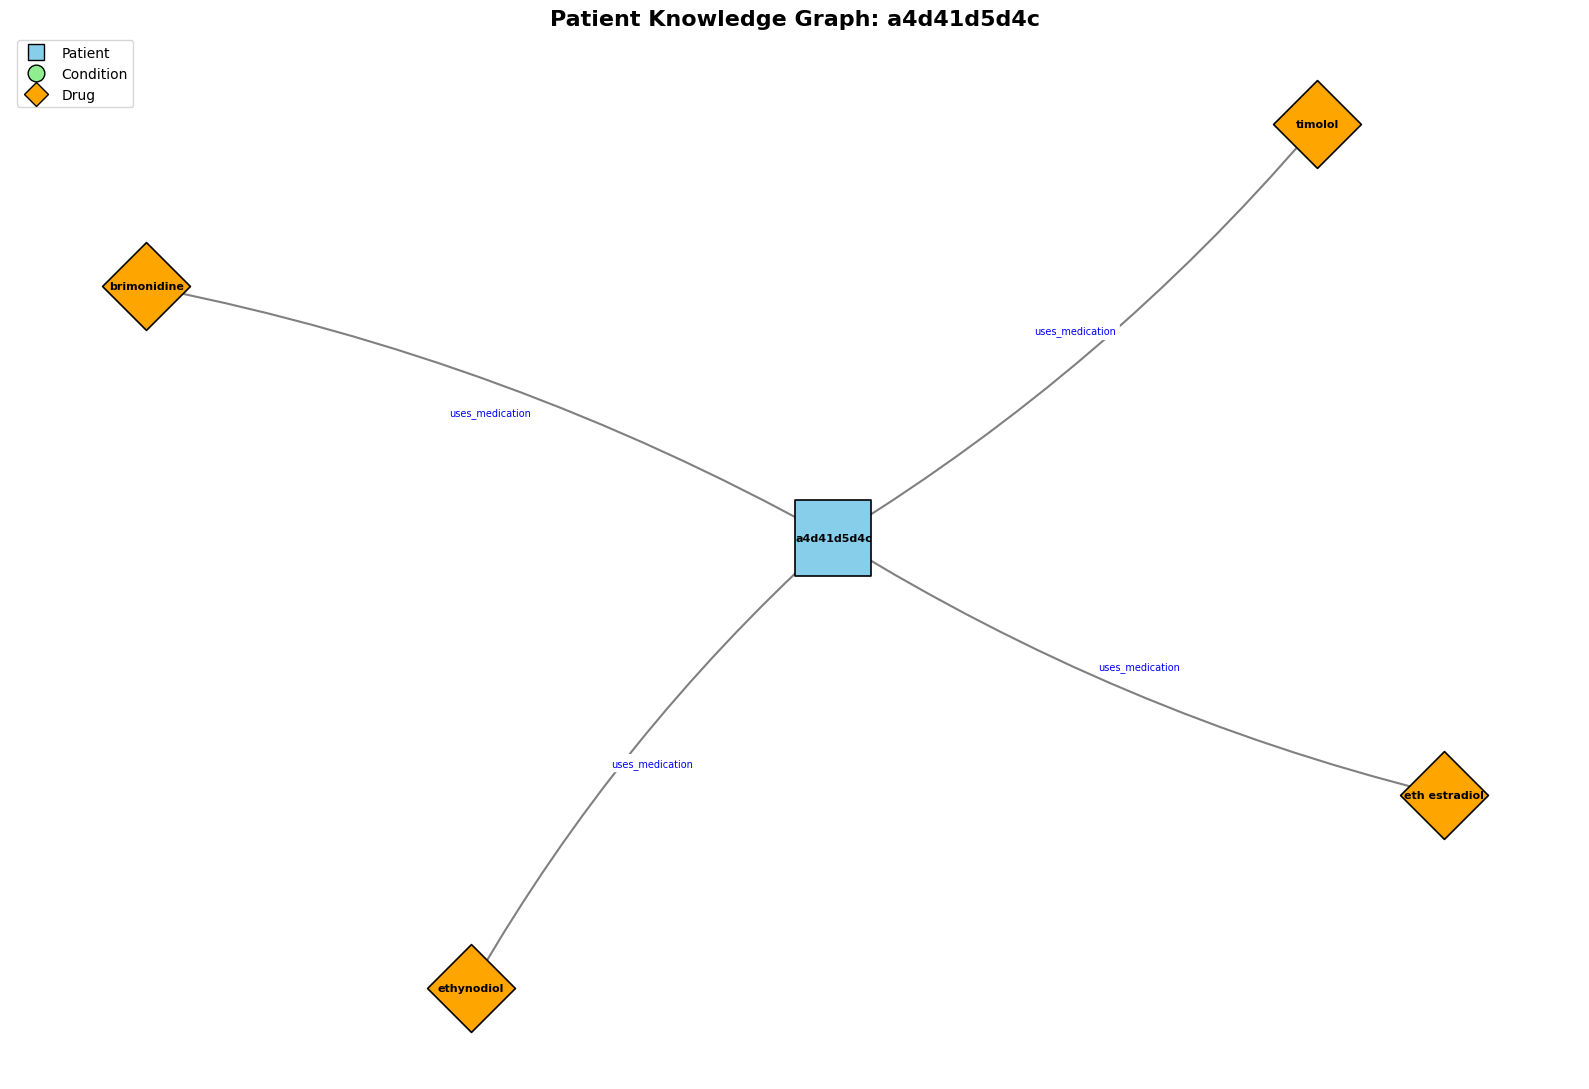

Saved: /content/output_graphs/a4d41d5d4c/a4d41d5d4c_knowledge_graph.png
Empty graph: Condition-Drug Relationship Graph: a4d41d5d4c
Condition-drug nodes: 0
Condition-drug edges: 0

PROCESSING PATIENT 2/5: b24c47659a
Conditions extracted: 0
Drugs extracted: 19
Total nodes: 20
Total edges: 19


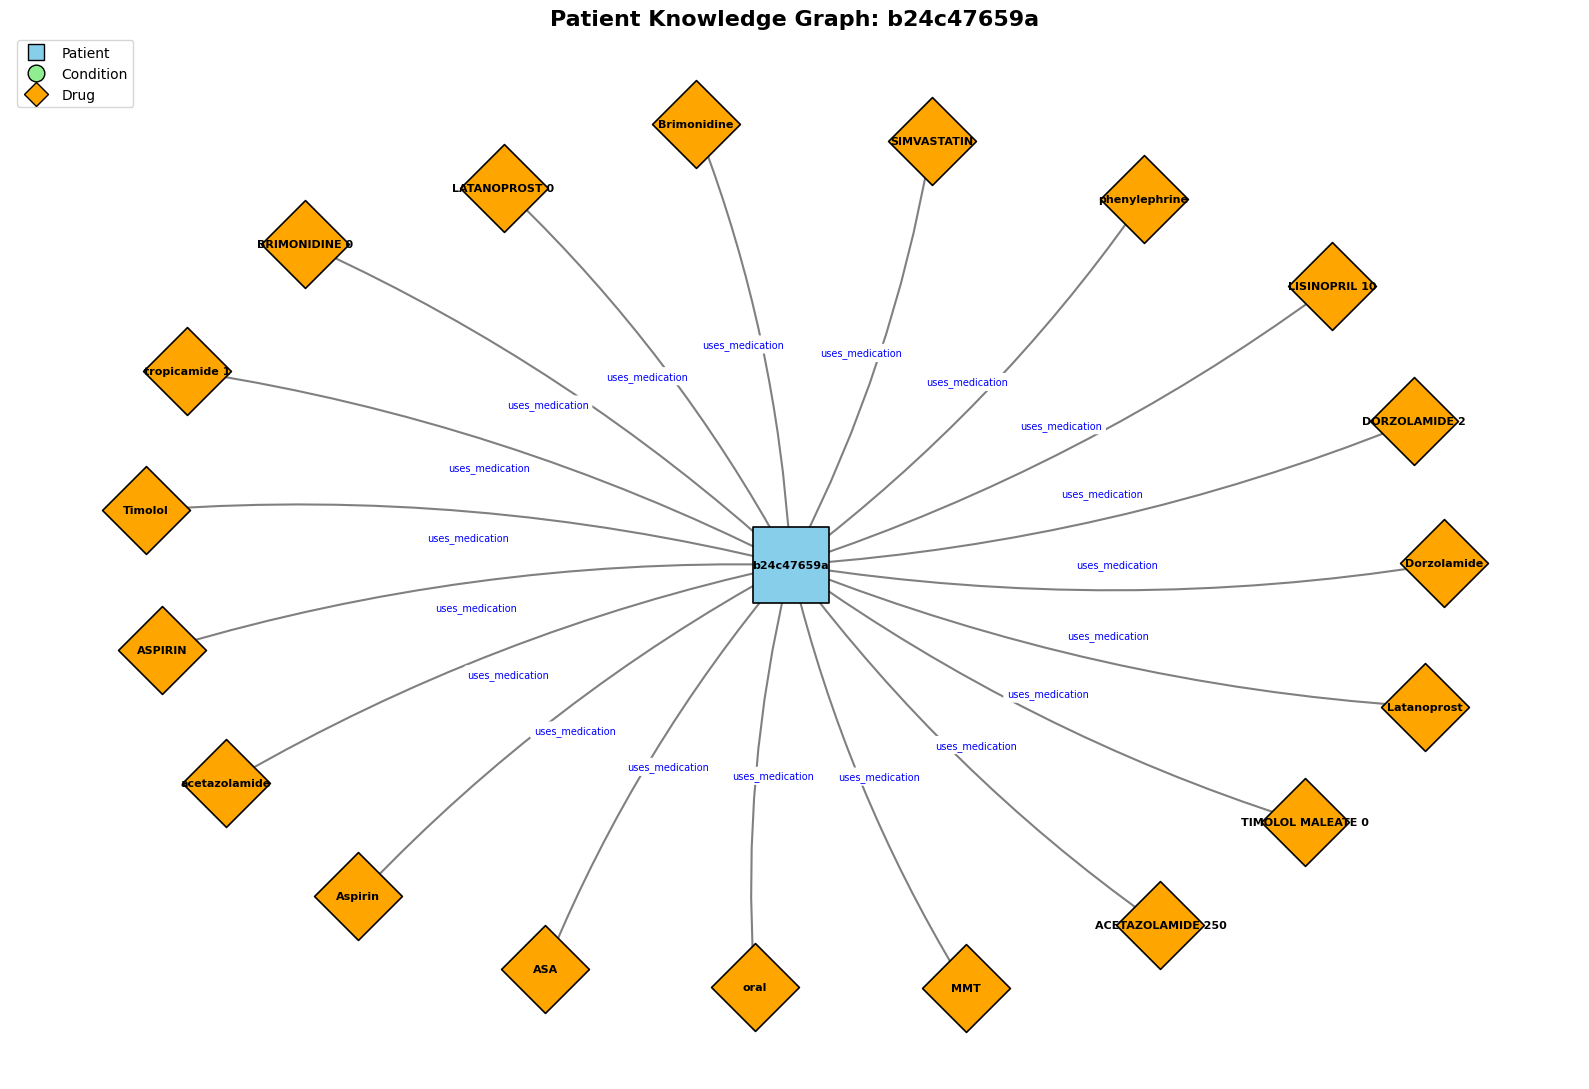

Saved: /content/output_graphs/b24c47659a/b24c47659a_knowledge_graph.png
Empty graph: Condition-Drug Relationship Graph: b24c47659a
Condition-drug nodes: 0
Condition-drug edges: 0

PROCESSING PATIENT 3/5: 120a864a1d
Conditions extracted: 0
Drugs extracted: 15
Total nodes: 16
Total edges: 15


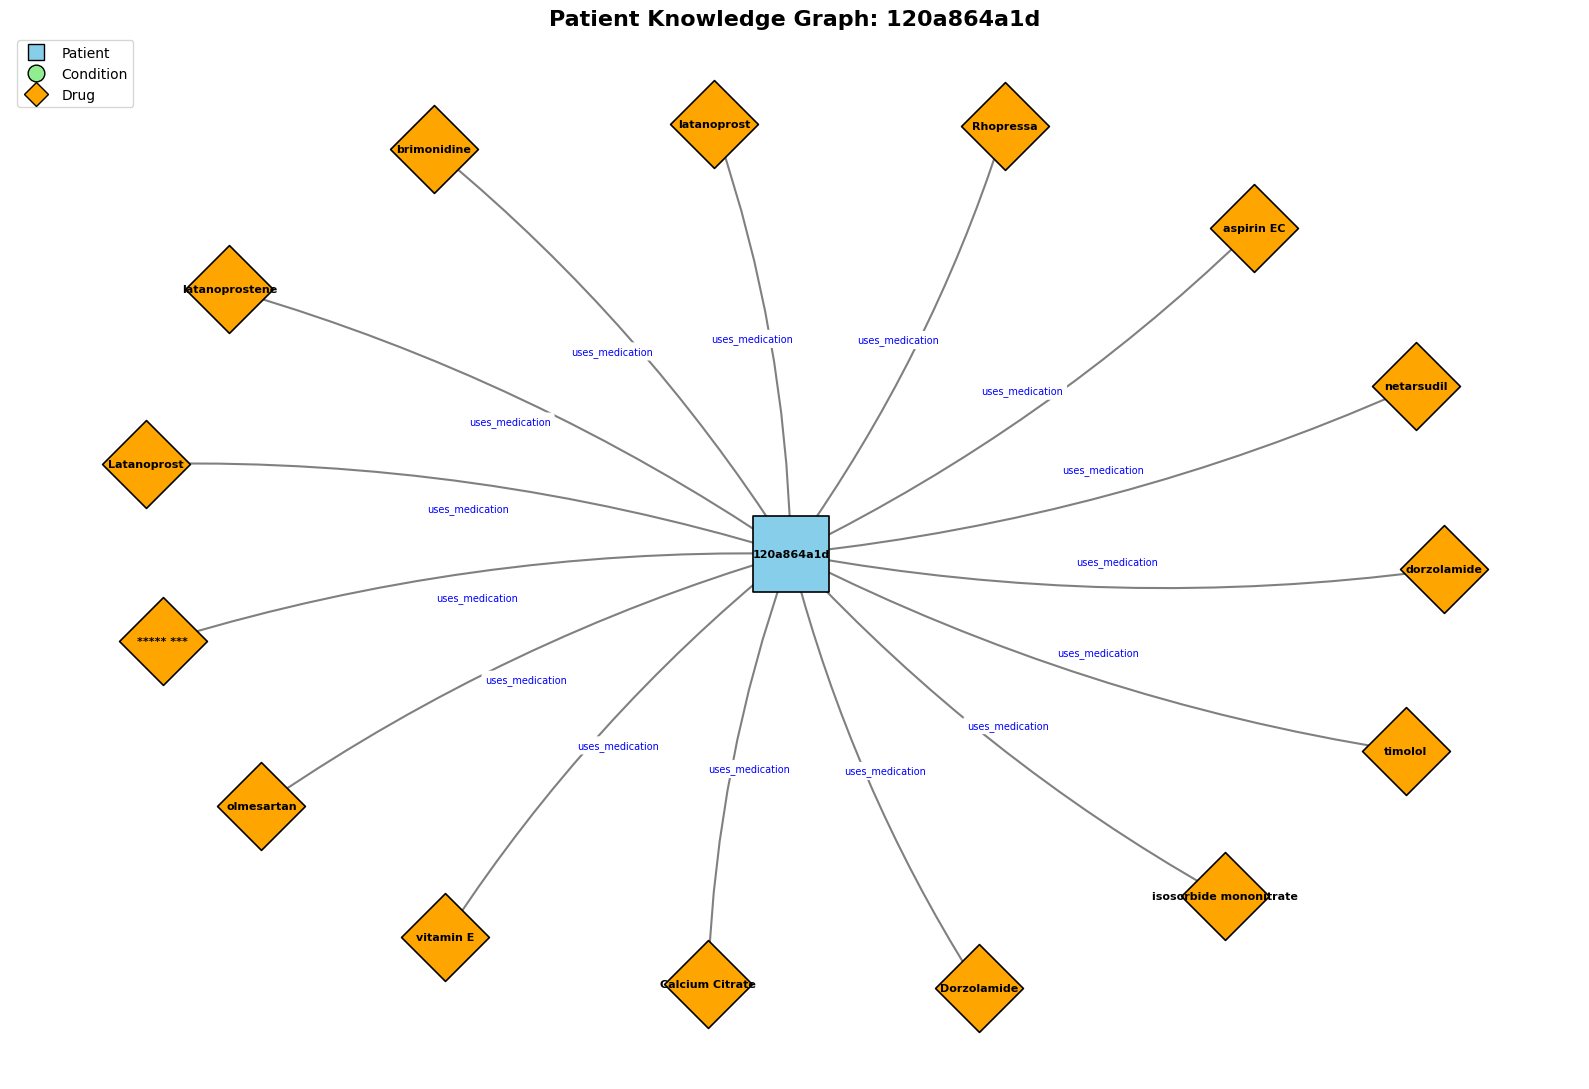

Saved: /content/output_graphs/120a864a1d/120a864a1d_knowledge_graph.png
Empty graph: Condition-Drug Relationship Graph: 120a864a1d
Condition-drug nodes: 0
Condition-drug edges: 0

PROCESSING PATIENT 4/5: f55a5ed0e2
Conditions extracted: 0
Drugs extracted: 11
Total nodes: 12
Total edges: 11


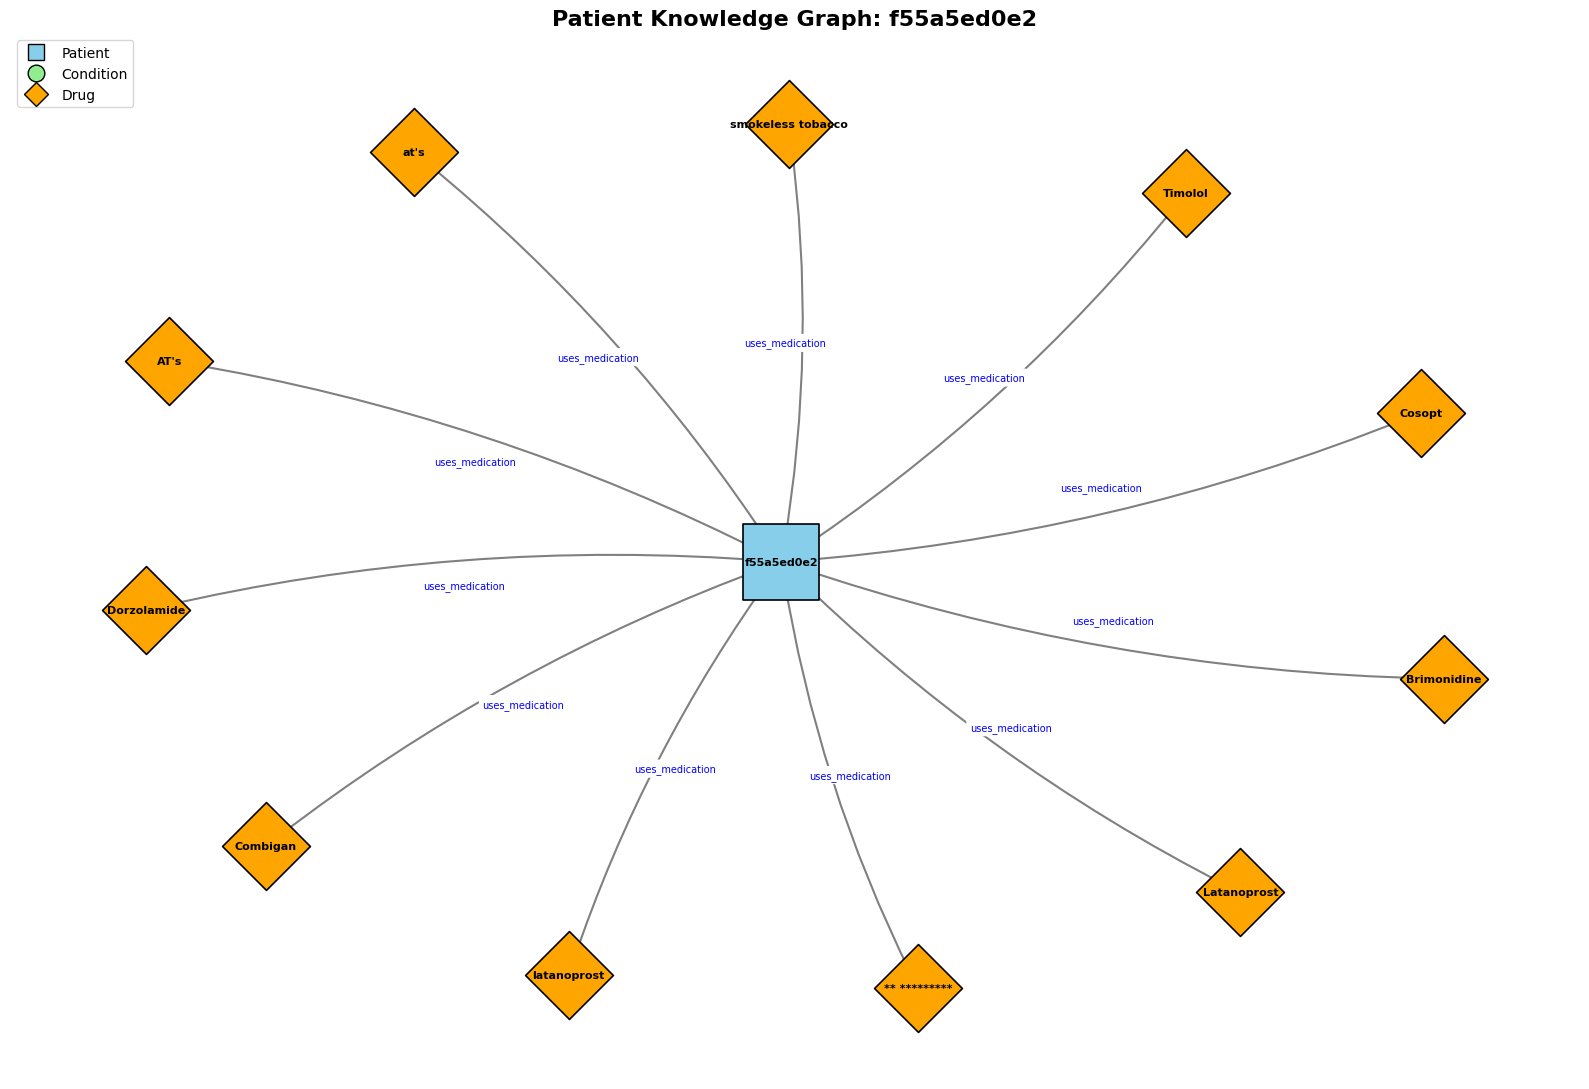

Saved: /content/output_graphs/f55a5ed0e2/f55a5ed0e2_knowledge_graph.png
Empty graph: Condition-Drug Relationship Graph: f55a5ed0e2
Condition-drug nodes: 0
Condition-drug edges: 0

PROCESSING PATIENT 5/5: f3624b10a6
Conditions extracted: 0
Drugs extracted: 16
Total nodes: 17
Total edges: 16


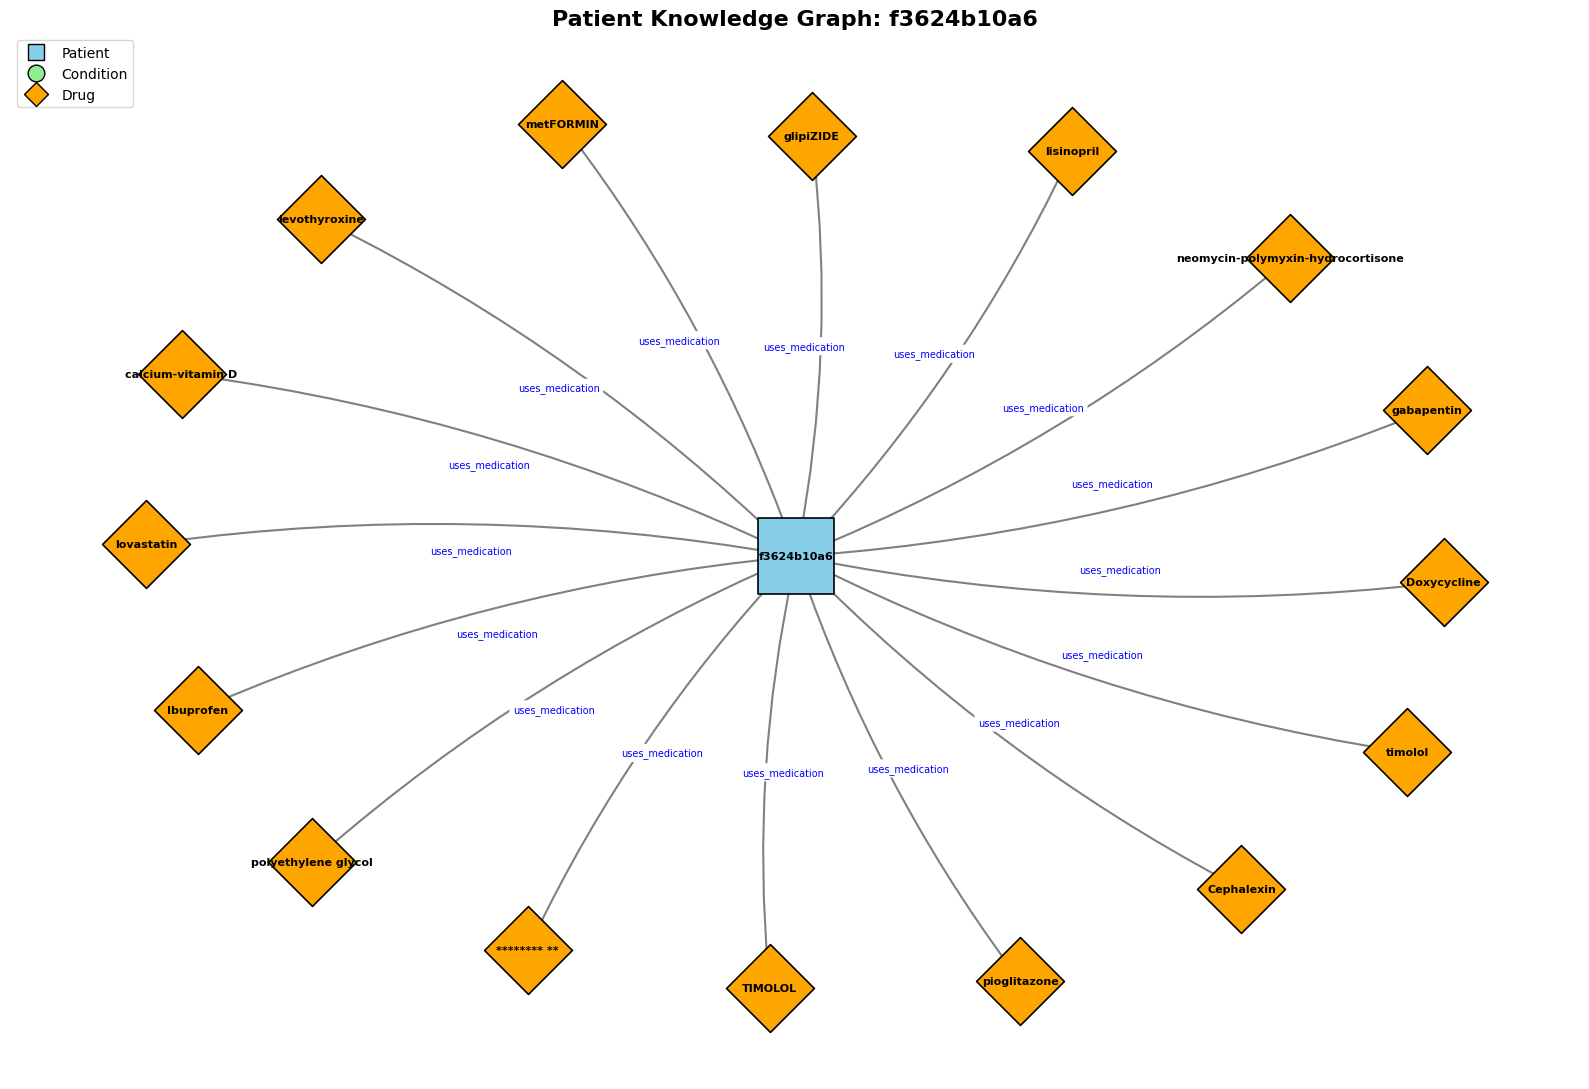

Saved: /content/output_graphs/f3624b10a6/f3624b10a6_knowledge_graph.png
Empty graph: Condition-Drug Relationship Graph: f3624b10a6
Condition-drug nodes: 0
Condition-drug edges: 0

ALL PATIENTS PROCESSED SUCCESSFULLY
Patients processed: 5
Combined graph nodes: 60
Combined graph edges: 65

Patient Metrics:
          File Patient ID  Conditions Extracted  Drugs Extracted  Total Nodes  Total Edges  Density
a4d41d5d4c.txt a4d41d5d4c                     0                4            5            4   0.2000
b24c47659a.txt b24c47659a                     0               19           20           19   0.0500
120a864a1d.txt 120a864a1d                     0               15           16           15   0.0625
f55a5ed0e2.txt f55a5ed0e2                     0               11           12           11   0.0833
f3624b10a6.txt f3624b10a6                     0               16           17           16   0.0588

Generated Individual Diagrams:
/content/output_graphs/combined_patient_knowledge_graph.png
/c

In [ ]:

import re
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from matplotlib.lines import Line2D


# ==========================================================
# 1. OUTPUT DIRECTORY AND INPUT FILES
# ==========================================================

OUTPUT_FOLDER = Path("/content/output_graphs")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

selected_files = note_files[:5]

print("Total patient files selected:", len(selected_files))


# ==========================================================
# 2. GRAPH METRICS
# ==========================================================

def calculate_graph_metrics(graph):

    return {
        "Total Nodes": graph.number_of_nodes(),
        "Total Edges": graph.number_of_edges(),
        "Density": round(nx.density(graph), 4)
    }


# ==========================================================
# 3. IDENTIFY NODE CATEGORY
# ==========================================================

def get_node_category(node, data):

    node_type = str(
        data.get("node_type")
        or data.get("type")
        or data.get("category")
        or ""
    ).lower()

    node_name = str(node).lower()

    if (
        "patient" in node_type
        or node_name.startswith("patient::")
    ):
        return "patient"

    if (
        "condition" in node_type
        or "disease" in node_type
        or node_name.startswith(("condition::", "disease::"))
    ):
        return "condition"

    if (
        "drug" in node_type
        or "medication" in node_type
        or node_name.startswith(("drug::", "medication::"))
    ):
        return "drug"

    return "other"


# ==========================================================
# 4. DRAW KNOWLEDGE GRAPH
# ==========================================================

def draw_knowledge_graph(graph, title, output_path):

    if graph.number_of_nodes() == 0:
        print("Empty graph:", title)
        return

    fig, ax = plt.subplots(figsize=(16, 11))

    # Classify nodes
    categories = {
        "patient": [],
        "condition": [],
        "drug": [],
        "other": []
    }

    for node, data in graph.nodes(data=True):

        category = get_node_category(node, data)
        categories[category].append(node)

    # Layout
    pos = nx.spring_layout(
        graph,
        seed=42,
        k=2.0,
        iterations=150
    )

    # Node styles
    styles = {
        "patient": {
            "color": "skyblue",
            "shape": "s",
            "size": 3000
        },
        "condition": {
            "color": "lightgreen",
            "shape": "o",
            "size": 2200
        },
        "drug": {
            "color": "orange",
            "shape": "D",
            "size": 2000
        },
        "other": {
            "color": "lightgray",
            "shape": "o",
            "size": 1800
        }
    }

    # Draw nodes separately
    for category, nodes in categories.items():

        if not nodes:
            continue

        style = styles[category]

        nx.draw_networkx_nodes(
            graph,
            pos,
            nodelist=nodes,
            node_color=style["color"],
            node_shape=style["shape"],
            node_size=style["size"],
            edgecolors="black",
            linewidths=1.2,
            ax=ax
        )

    # Node labels
    labels = {}

    for node, data in graph.nodes(data=True):

        labels[node] = data.get(
            "label",
            str(node).replace("PATIENT::", "")
        )

    nx.draw_networkx_labels(
        graph,
        pos,
        labels=labels,
        font_size=8,
        font_weight="bold",
        ax=ax
    )

    # Edges
    nx.draw_networkx_edges(
        graph,
        pos,
        edge_color="gray",
        width=1.5,
        arrows=True,
        arrowsize=18,
        connectionstyle="arc3,rad=0.08",
        ax=ax
    )

    # Relationship labels
    edge_labels = {}

    for source, target, data in graph.edges(data=True):

        relation = data.get("relation", "")

        if relation:
            edge_labels[(source, target)] = relation

    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=edge_labels,
        font_size=7,
        font_color="blue",
        rotate=False,
        label_pos=0.5,
        ax=ax
    )

    # Legend
    legend_elements = [
        Line2D(
            [0], [0],
            marker="s",
            color="w",
            label="Patient",
            markerfacecolor="skyblue",
            markeredgecolor="black",
            markersize=12
        ),
        Line2D(
            [0], [0],
            marker="o",
            color="w",
            label="Condition",
            markerfacecolor="lightgreen",
            markeredgecolor="black",
            markersize=12
        ),
        Line2D(
            [0], [0],
            marker="D",
            color="w",
            label="Drug",
            markerfacecolor="orange",
            markeredgecolor="black",
            markersize=12
        )
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper left",
        fontsize=10
    )

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold"
    )

    ax.axis("off")
    plt.tight_layout()

    # Save diagram
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


# ==========================================================
# 5. CREATE CONDITION-DRUG GRAPH FOR EACH PATIENT
# ==========================================================

def create_condition_drug_graph(patient_graph):

    cd_graph = nx.DiGraph()

    valid_relations = [
        "treated_with",
        "co_mentioned_with",
        "co_prescribed_with"
    ]

    for source, target, data in patient_graph.edges(data=True):

        relation = data.get("relation", "")

        if relation not in valid_relations:
            continue

        source_type = get_node_category(
            source,
            patient_graph.nodes[source]
        )

        target_type = get_node_category(
            target,
            patient_graph.nodes[target]
        )

        valid_pair = (
            source_type == "condition" and target_type == "drug"
        ) or (
            source_type == "drug" and target_type == "condition"
        )

        if valid_pair:

            cd_graph.add_node(
                source,
                **patient_graph.nodes[source]
            )

            cd_graph.add_node(
                target,
                **patient_graph.nodes[target]
            )

            cd_graph.add_edge(
                source,
                target,
                **data
            )

    return cd_graph


# ==========================================================
# 6. PROCESS ALL PATIENT NOTES
# ==========================================================

combined_graph = nx.DiGraph()

all_patient_metrics = []
all_entity_records = []
all_relationship_records = []

for index, note_file in enumerate(selected_files, start=1):

    patient_id = note_file.stem

    print("\n" + "=" * 75)
    print(
        f"PROCESSING PATIENT {index}/{len(selected_files)}: "
        f"{patient_id}"
    )
    print("=" * 75)

    # Read clinical note
    with open(
        note_file,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as file:

        note_text = file.read()

    # Build patient knowledge graph
    patient_graph, diseases, drugs = build_patient_knowledge_graph(
        patient_id,
        note_text
    )

    # Calculate metrics
    metrics = calculate_graph_metrics(patient_graph)

    print("Conditions extracted:", len(diseases))
    print("Drugs extracted:", len(drugs))
    print("Total nodes:", metrics["Total Nodes"])
    print("Total edges:", metrics["Total Edges"])

    # Individual patient folder
    patient_folder = OUTPUT_FOLDER / patient_id
    patient_folder.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------
    # A. INDIVIDUAL PATIENT KNOWLEDGE GRAPH
    # ------------------------------------------------------

    patient_graph_path = (
        patient_folder / f"{patient_id}_knowledge_graph.png"
    )

    draw_knowledge_graph(
        patient_graph,
        f"Patient Knowledge Graph: {patient_id}",
        patient_graph_path
    )

    # ------------------------------------------------------
    # B. INDIVIDUAL CONDITION-DRUG RELATIONSHIP GRAPH
    # ------------------------------------------------------

    condition_drug_graph = create_condition_drug_graph(
        patient_graph
    )

    condition_graph_path = (
        patient_folder / f"{patient_id}_condition_drug_graph.png"
    )

    draw_knowledge_graph(
        condition_drug_graph,
        f"Condition-Drug Relationship Graph: {patient_id}",
        condition_graph_path
    )

    print(
        "Condition-drug nodes:",
        condition_drug_graph.number_of_nodes()
    )

    print(
        "Condition-drug edges:",
        condition_drug_graph.number_of_edges()
    )

    # ------------------------------------------------------
    # C. PATIENT METRICS
    # ------------------------------------------------------

    all_patient_metrics.append({
        "File": note_file.name,
        "Patient ID": patient_id,
        "Conditions Extracted": len(diseases),
        "Drugs Extracted": len(drugs),
        **metrics
    })

    # ------------------------------------------------------
    # D. ENTITY RECORDS
    # ------------------------------------------------------

    for disease in diseases:

        all_entity_records.append({
            "Patient ID": patient_id,
            "Entity": disease,
            "Entity Type": "Condition"
        })

    for drug in drugs:

        all_entity_records.append({
            "Patient ID": patient_id,
            "Entity": drug,
            "Entity Type": "Drug"
        })

    # ------------------------------------------------------
    # E. RELATIONSHIP RECORDS
    # ------------------------------------------------------

    for source, target, data in patient_graph.edges(data=True):

        all_relationship_records.append({
            "Patient ID": patient_id,
            "Source": source,
            "Target": target,
            "Relationship": data.get("relation", ""),
            "Evidence": data.get("evidence", "")
        })

    # ------------------------------------------------------
    # F. MERGE GRAPHS FOR OPTIONAL OVERALL ANALYSIS
    # ------------------------------------------------------

    combined_graph = nx.compose(
        combined_graph,
        patient_graph
    )


# ==========================================================
# 7. SAVE CSV REPORTS
# ==========================================================

metrics_df = pd.DataFrame(all_patient_metrics)
entities_df = pd.DataFrame(all_entity_records)
relationships_df = pd.DataFrame(all_relationship_records)

metrics_df.to_csv(
    OUTPUT_FOLDER / "patient_metrics.csv",
    index=False
)

entities_df.to_csv(
    OUTPUT_FOLDER / "patient_entities.csv",
    index=False
)

relationships_df.to_csv(
    OUTPUT_FOLDER / "patient_relationships.csv",
    index=False
)


# ==========================================================
# 8. FINAL SUMMARY
# ==========================================================

print("\n" + "=" * 75)
print("ALL PATIENTS PROCESSED SUCCESSFULLY")
print("=" * 75)

print("Patients processed:", len(selected_files))

print(
    "Combined graph nodes:",
    combined_graph.number_of_nodes()
)

print(
    "Combined graph edges:",
    combined_graph.number_of_edges()
)

print("\nPatient Metrics:")
print(metrics_df.to_string(index=False))

print("\nGenerated Individual Diagrams:")

for image_file in OUTPUT_FOLDER.rglob("*.png"):
    print(image_file)

print("\nGenerated CSV Files:")

for csv_file in OUTPUT_FOLDER.glob("*.csv"):
    print(csv_file)

print("\nOutput directory:", OUTPUT_FOLDER)


In [ ]:
from pathlib import Path
import pandas as pd

# Path to the complete dataset
NOTES_DIR = Path("/content/Glaucoma_Med_Dataset/Deidentified_Notes")

# Load every patient clinical note
selected_files = sorted(NOTES_DIR.glob("*.txt"))

print("Total patient files:", len(selected_files))

Total patient files: 480


In [ ]:
all_patient_metrics = []
all_entity_records = []
all_relationship_records = []

combined_graph = nx.DiGraph()

for index, note_file in enumerate(selected_files, start=1):

    patient_id = note_file.stem

    with open(note_file, "r", encoding="utf-8") as f:
        note_text = f.read()

    # Build patient knowledge graph
    patient_graph, diseases, drugs = build_patient_knowledge_graph(
        patient_id, note_text
    )

    # Calculate patient graph metrics
    metrics = calculate_graph_metrics(patient_graph)

    metrics["File"] = note_file.name
    metrics["Patient ID"] = patient_id
    metrics["Conditions Extracted"] = len(diseases)
    metrics["Drugs Extracted"] = len(drugs)

    all_patient_metrics.append(metrics)

    # Store entity records
    # Keep your existing entity-record collection code here.

    # Store relationship records
    for source, target, data in patient_graph.edges(data=True):
        all_relationship_records.append({
            "Patient ID": patient_id,
            "Source": source,
            "Target": target,
            "Relationship": data.get("relation", ""),
            "Evidence": data.get("evidence", "")
        })

    # Combine individual patient graphs
    combined_graph = nx.compose(combined_graph, patient_graph)

    print(f"Processed {index}/{len(selected_files)}: {patient_id}")

Processed 1/480: 01655bde5b
Processed 2/480: 01dcccc1a1
Processed 3/480: 0217483bd3
Processed 4/480: 025920c6c9
Processed 5/480: 0333bead9c
Processed 6/480: 04bd960ee3
Processed 7/480: 04f61bdb82
Processed 8/480: 0576b0da32
Processed 9/480: 058de1cfe4
Processed 10/480: 058fdc04d7
Processed 11/480: 05c599c01f
Processed 12/480: 05de1ee6aa
Processed 13/480: 063a1e7221
Processed 14/480: 0642ed9a5c
Processed 15/480: 07ecc5c996
Processed 16/480: 08073fc351
Processed 17/480: 085af3de1f
Processed 18/480: 08b9d6c2bc
Processed 19/480: 08fea8a075
Processed 20/480: 09d49609d3
Processed 21/480: 0b50c6e1a0
Processed 22/480: 0b63b49bef
Processed 23/480: 0c88d20b0e
Processed 24/480: 0ca87d3fd3
Processed 25/480: 0cf67aeb66
Processed 26/480: 0d1b09d71f
Processed 27/480: 0e1bd6151f
Processed 28/480: 0ee9ebbcaa
Processed 29/480: 0efe85106c
Processed 30/480: 0f1fcc3b19
Processed 31/480: 0f6b334bf3
Processed 32/480: 10321e6881
Processed 33/480: 1033add132
Processed 34/480: 10448e84dd
Processed 35/480: 10d26

In [ ]:
metrics_dataframe = pd.DataFrame(all_patient_metrics)

display(metrics_dataframe)

metrics_dataframe.to_csv(
    OUTPUT_FOLDER / "patient_metrics.csv",
    index=False
)

print("Patient metrics saved!")
print("Total patients processed:", len(metrics_dataframe))

,Total Nodes,Total Edges,Average Degree,Density,Average Clustering Coefficient,Average Shortest Path Length,Weakly Connected Components,File,Patient ID,Conditions Extracted,Drugs Extracted
0,11,10,1.8182,0.1818,0.0,1.8182,1,01655bde5b.txt,01655bde5b,0,10
1,13,12,1.8462,0.1538,0.0,1.8462,1,01dcccc1a1.txt,01dcccc1a1,0,12
2,34,33,1.9412,0.0588,0.0,1.9412,1,0217483bd3.txt,0217483bd3,0,33
3,17,16,1.8824,0.1176,0.0,1.8824,1,025920c6c9.txt,025920c6c9,0,16
4,15,14,1.8667,0.1333,0.0,1.8667,1,0333bead9c.txt,0333bead9c,0,14
...,...,...,...,...,...,...,...,...,...,...,...
475,22,21,1.9091,0.0909,0.0,1.9091,1,fc85e15ebc.txt,fc85e15ebc,0,21
476,20,19,1.9000,0.1000,0.0,1.9000,1,fcc67e3df1.txt,fcc67e3df1,0,19
477,3,2,1.3333,0.6667,0.0,1.3333,1,fd5ff71168.txt,fd5ff71168,0,2
478,6,5,1.6667,0.3333,0.0,1.6667,1,fe8d5a3c29.txt,fe8d5a3c29,0,5


Patient metrics saved!
Total patients processed: 480
